# Task 01: Introduction to PyTorch

## Introduction

The goal of this task is to get us thinking not just about training models, but about our *training pipelines*.

A neural network is a function, $f$, that accepts data inputs, $\boldsymbol{X}$, and weights, $\boldsymbol{\Theta}$ that produces predictions $\boldsymbol{\hat{y}}$,

$$
\boldsymbol{\hat{y}} = f(\boldsymbol{\Theta}; \boldsymbol{X}).
$$

Meanwhile, a neural network training process is itself a function, $g$, which accepts as input a dataset $\boldsymbol{X}$, and for supervised algorithms a set of targets $y$, along with a set of training configuration hyperparameters $\boldsymbol{\Omega}$ which define how the process is performed, and produces as output the weights of a neural network, $\boldsymbol{\Theta}$,

$$
\boldsymbol{\Theta} = g(\boldsymbol{\Omega}; \boldsymbol{X}, \boldsymbol{y}).
$$

It is helpful to think of the training function, $g$, as a pipeline, composed of several training steps, which can include preprocessing, post-processing, etc.

$$
g = g_N \circ\ \cdots\ \circ g_1.
$$

For example, $g_1$ might be a preprocessing step, then $g_2$ might be a training step, and $g_3$ might be a pruning step in a basic pipeline where data $(\boldsymbol{X}, \boldsymbol{y})$ goes in and weights $\boldsymbol{\Theta}$ come out.

Generally, we separate out a training, validation, and testing set. For MNIST, there is an official test set, so we split the training set into training and validation portions. The training set is used to estimate $\boldsymbol{\Theta}$, the parameters of the network. The validation set is used to choose $\boldsymbol{\Omega}$, the hyperparameters of the training process itself. The test data is held out entirely to estimate final performance.

We will learn to think of the training process this way by modifying some example code for a basic MNIST classification task. We begin with some imports.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from dataclasses import dataclass

import torch
import torch.nn.functional as F
from torch import nn, optim
from torch.optim.lr_scheduler import StepLR
from torchvision import datasets, transforms


## Task 01 - Part 1

Your first task is to:

* Add layer definitions to the following neural network class
* Define the forward pass

You can find starting architectures online. It is important to know there is not a complete theory to identify a best architecture before starting the problem. Trial and error (by iterative training and experimentation) is generally required to prove or disprove the utility of an architecture.

Recall some of our intuition about the way linear and nonlinear transforms work. Chaining linear transforms together simplifies into another linear transform which does not increase the space of functions our network can support. The space of functions a network can support is also called the *hypothesis space*. The number of layers, width of those layers, and types of transformations employed are all therefore architecture design choices we can explore experimentally to find a suitable model for our task from the space of possible models we could have chosen.

**IMPORTANT:** The starter code assumes that your network accepts an MNIST image as input and returns a tensor containing 10 output values for each image, one for each digit class (0 through 9).


In [2]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        return self.network(x)


def run_training_epoch(
    training_params, model, device, train_loader, optimizer, epoch
):
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = F.cross_entropy(output, target)
        loss.backward()
        optimizer.step()
        if batch_idx % training_params.log_interval == 0:
            print(
                f"Train Epoch: {epoch} [{batch_idx * len(data)}/{len(train_loader.dataset)} ({100.0 * batch_idx / len(train_loader):.0f}%)]\tLoss: {loss.item():.6f}"
            )
            if training_params.dry_run:
                break


def evaluate(model, device, data_loader, dataset_name="Test"):
    model.eval()
    loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in data_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            loss += F.cross_entropy(
                output, target, reduction="sum"
            ).item()  # sum up batch loss
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

    loss /= len(data_loader.dataset)

    print(
        f"\n{dataset_name} set: Average loss: {loss:.4f}, Accuracy: {correct}/{len(data_loader.dataset)} ({100.0 * correct / len(data_loader.dataset):.0f}%)\n"
    )
    return loss

## Helper Code: Training Pipeline

For this assignment, the training pipeline is defined for you. Notice the similarities to the mathematical description of a trainer we saw above.

In [3]:
@dataclass
class TrainingParameters:
    """Training parameters for a simple neural network trainer."""

    batch_size: int = 64
    test_batch_size: int = 1000
    epochs: int = 14
    lr: float = 1.0
    gamma: float = 0.7
    normalizer_mean: float = 0.1307
    normalizer_std: float = 0.3081
    no_cuda: bool = True  # Disable CUDA
    no_mps: bool = True  # Disable GPU on MacOS
    dry_run: bool = False
    seed: int = 1
    log_interval: int = 10
    save_model: bool = True


def configure_training_device(training_params):
    use_cuda = not training_params.no_cuda and torch.cuda.is_available()
    use_mps = not training_params.no_mps and torch.backends.mps.is_available()

    torch.manual_seed(training_params.seed)

    if use_cuda:
        device = torch.device("cuda")
    elif use_mps:
        device = torch.device("mps")
    else:
        device = torch.device("cpu")

    train_kwargs = {
        "batch_size": training_params.batch_size,
        "shuffle": True,
    }

    test_kwargs = {
        "batch_size": training_params.test_batch_size,
        "shuffle": False,
    }

    if use_cuda:
        cuda_kwargs = {
            "num_workers": 1,
            "pin_memory": True,
        }
        train_kwargs.update(cuda_kwargs)
        test_kwargs.update(cuda_kwargs)

    return device, train_kwargs, test_kwargs


def build_preprocessing_transform(training_params):
    transform = transforms.Compose(
        [
            transforms.ToTensor(),
            transforms.Normalize(
                (training_params.normalizer_mean,),
                (training_params.normalizer_std,),
            ),
        ]
    )

    return transform


def build_data_loaders(train_kwargs, test_kwargs, transform):
    train_dataset = datasets.MNIST(
        "../data", train=True, download=True, transform=transform
    )
    test_dataset = datasets.MNIST(
        "../data", train=False, download=True, transform=transform
    )

    train_data, val_data = torch.utils.data.random_split(
        train_dataset, [0.9, 0.1], generator=torch.Generator().manual_seed(1)
    )
    train_loader = torch.utils.data.DataLoader(train_data, **train_kwargs)
    val_loader = torch.utils.data.DataLoader(val_data, **test_kwargs)
    test_loader = torch.utils.data.DataLoader(test_dataset, **test_kwargs)
    return train_loader, val_loader, test_loader


def train(training_params, device, train_loader, val_loader):
    model = Net().to(device)
    optimizer = optim.Adadelta(model.parameters(), lr=training_params.lr)
    scheduler = StepLR(optimizer, step_size=1, gamma=training_params.gamma)
    best_validation_loss = float("inf")

    for epoch in range(1, training_params.epochs + 1):
        run_training_epoch(
            training_params, model, device, train_loader, optimizer, epoch
        )
        validation_loss = evaluate(
            model, device, val_loader, dataset_name="Validation"
        )
        scheduler.step()

        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            if training_params.save_model:
                torch.save(model.state_dict(), "mnist_model.pt")

## Example: Execute a Training Pipeline

With our training steps defined in modular fashion, we can easily define and execute a training pipeline.

Recall the training pipeline is defined by

$$
\Theta = g(\boldsymbol{\Omega}; \boldsymbol{X}, \boldsymbol{y}).
$$


In [4]:
def execute_training_pipeline():
    training_params = TrainingParameters(
        epochs=1, dry_run=True, save_model=False
    )
    device, train_kwargs, test_kwargs = configure_training_device(
        training_params
    )
    transform = build_preprocessing_transform(training_params)
    train_loader, val_loader, _ = build_data_loaders(
        train_kwargs, test_kwargs, transform
    )
    train(training_params, device, train_loader, val_loader)


## Example: Execute an Evaluation Pipeline

With the training pipeline defined, we can run an evaluation pipeline on the test data. Save this pipeline for when you are ready to test your model.

The evaluation pipeline, $h$, accepts a set of model weights, along with a test set and test targets, and then produces a vector of performance metrics, $\boldsymbol{\mu}$.

$$
\boldsymbol{\mu} = h(\boldsymbol{\Theta}, \boldsymbol{X}_{\mathrm{TEST}}, \boldsymbol{y}_{\mathrm{TEST}})
$$

In [5]:
def execute_evaluation_pipeline():
    training_params = TrainingParameters()

    device, train_kwargs, test_kwargs = configure_training_device(
        training_params
    )
    transform = build_preprocessing_transform(training_params)
    _, _, test_loader = build_data_loaders(
        train_kwargs, test_kwargs, transform
    )
    model = Net().to(device)
    model.load_state_dict(
        torch.load("mnist_model.pt", map_location=device, weights_only=True)
    )
    evaluate(model, device, test_loader)


## Task 01 - Part 2: Explore Width

Using the example above, define a neural network with a single hidden layer.

Modify the training pipeline to store the training and validation loss after each epoch.

Create a loop that iterates through several different hidden-layer widths. For each width:

* Create a new model.
* Train the model until convergence, or until the validation loss no longer improves for several epochs.
* Record the minimum validation loss achieved during training.

Plot the minimum validation loss with respect to the number of neurons in the hidden layer.

Use your results to describe how changing the width of the hidden layer affects the performance of the model.


Hidden size 8: best validation loss = 0.2830
Hidden size 16: best validation loss = 0.1932
Hidden size 32: best validation loss = 0.1297
Hidden size 64: best validation loss = 0.0936
Hidden size 128: best validation loss = 0.0760
Hidden size 256: best validation loss = 0.0664


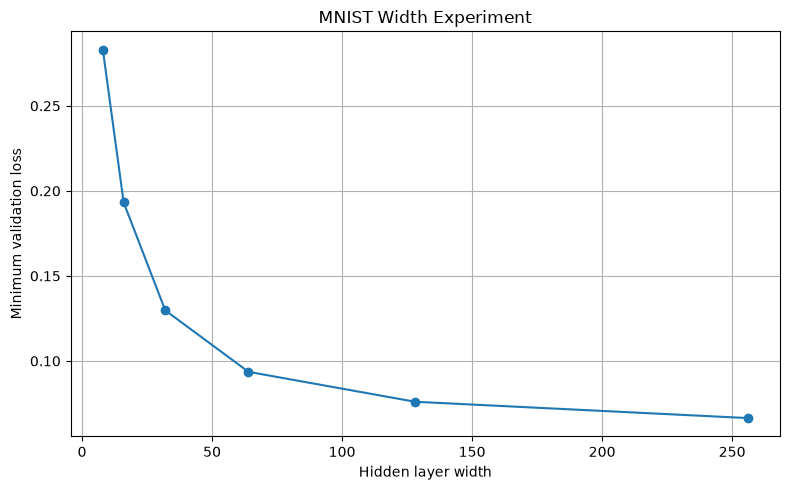

In [ ]:
import copy
import io
import contextlib
import matplotlib.pyplot as plt


class SingleHiddenLayerNet(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, 10),
        )

    def forward(self, x):
        return self.network(x)


def run_training_epoch_tracking(training_params, model, device, train_loader, optimizer):
    model.train()
    total_loss = 0.0
    total_examples = 0

    for data, target in train_loader:
        data, target = data.to(device), target.to(device)

        optimizer.zero_grad()
        output = model(data)
        loss = F.cross_entropy(output, target)

        total_loss += loss.item() * data.size(0)
        total_examples += data.size(0)

        loss.backward()
        optimizer.step()

    return total_loss / total_examples


def train_and_track_width(hidden_size, training_params, device, train_loader, val_loader):
    model = SingleHiddenLayerNet(hidden_size).to(device)

    optimizer = optim.Adadelta(
        model.parameters(),
        lr=training_params.lr
    )

    scheduler = StepLR(
        optimizer,
        step_size=1,
        gamma=training_params.gamma
    )

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_state = None
    epochs_without_improvement = 0
    patience = 2

    for epoch in range(1, training_params.epochs + 1):
        train_loss = run_training_epoch_tracking(
            training_params,
            model,
            device,
            train_loader,
            optimizer
        )

        train_losses.append(train_loss)

        # Hide the repeated validation output so the graph can display
        with contextlib.redirect_stdout(io.StringIO()):
            val_loss = evaluate(
                model,
                device,
                val_loader,
                dataset_name="Validation"
            )

        val_losses.append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        scheduler.step()

        if epochs_without_improvement >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, train_losses, val_losses, best_val_loss


widths = [8, 16, 32, 64, 128, 256]
width_results = []

for width in widths:
    training_params = TrainingParameters(
    epochs=10,
    batch_size=256,
    test_batch_size=1000,
    lr=1.0,
    gamma=0.7,
    dry_run=False,
    save_model=False,

    )

    device, train_kwargs, test_kwargs = configure_training_device(
        training_params
    )

    transform = build_preprocessing_transform(training_params)

    train_loader, val_loader, _ = build_data_loaders(
        train_kwargs,
        test_kwargs,
        transform
    )

    model, train_losses, val_losses, best_val_loss = train_and_track_width(
        width,
        training_params,
        device,
        train_loader,
        val_loader
    )

    width_results.append(
        (width, best_val_loss, train_losses, val_losses)
    )

    print(
        f"Hidden size {width}: "
        f"best validation loss = {best_val_loss:.4f}"
    )


plt.figure(figsize=(8, 5))

plt.plot(
    [width for width, _, _, _ in width_results],
    [best for _, best, _, _ in width_results],
    marker="o"
)

plt.xlabel("Hidden layer width")
plt.ylabel("Minimum validation loss")
plt.title("MNIST Width Experiment")
plt.grid(True)
plt.tight_layout()
plt.show()

**Explination of Code and assignment findings** 

This experiment investigates how the number of neurons in a single hidden layer affects the performance of a neural network on MNIST. The SingleHiddenLayerNet class creates a network with an input layer, one hidden layer using ReLU activation, and an output layer with 10 classes.

For each hidden-layer width in [8, 16, 32, 64, 128, 256], a new model is created and trained. The training and validation loss are recorded after every epoch. The model uses early stopping: training stops when the validation loss fails to improve for three consecutive epochs. The best model parameters and minimum validation loss are saved.

Finally, the minimum validation loss for each hidden-layer width is plotted. The graph shows that increasing the hidden-layer width generally decreases the validation loss. This means wider hidden layers provide the model with greater capacity to learn patterns in the images. However, the improvements become smaller at larger widths. In this experiment, the 256-neuron hidden layer achieved the lowest validation loss.


## Task 01 - Part 3: Explore Depth

Now explore the effect of **network depth**.

Using the example above, define several neural networks with increasing numbers of hidden layers.

Try to keep the other architectural choices approximately constant so that the primary variable being changed is the depth of the network.

Create a loop that iterates through several different network depths. For each depth:

* Create a new model.
* Train the model until convergence, or until the validation loss no longer improves for several epochs.
* Record the minimum validation loss achieved during training.

Plot the minimum validation loss with respect to the number of hidden layers.

Use your results to describe how changing the depth of the network affects model performance.


Depth 1: best validation loss = 0.0936
Depth 2: best validation loss = 0.0878
Depth 3: best validation loss = 0.0863
Depth 4: best validation loss = 0.0967
Depth 5: best validation loss = 0.0978


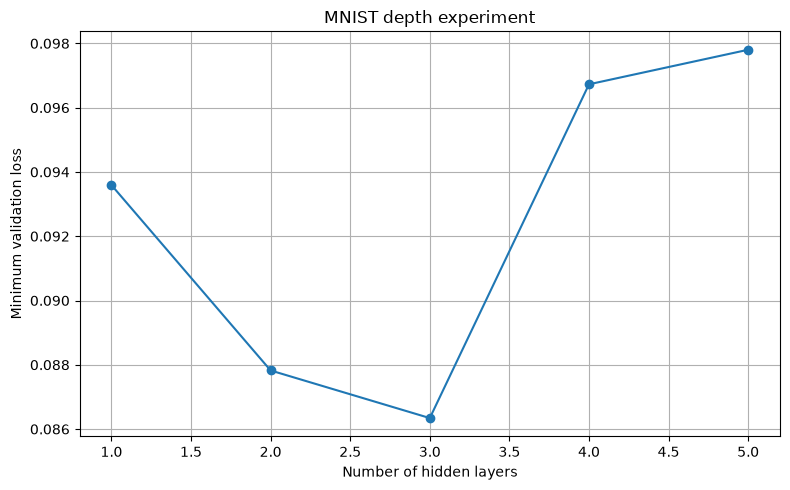

In [10]:
import copy
import io
import contextlib
import matplotlib.pyplot as plt


class DepthNetwork(nn.Module):
    def __init__(self, hidden_layers, hidden_size=64):
        super().__init__()
        layers = [
            nn.Flatten(),
            nn.Linear(28 * 28, hidden_size),
            nn.ReLU(),
        ]

        for _ in range(hidden_layers - 1):
            layers.extend([nn.Linear(hidden_size, hidden_size), nn.ReLU()])

        layers.append(nn.Linear(hidden_size, 10))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def train_and_track_depth(hidden_layers, training_params, device, train_loader, val_loader):
    model = DepthNetwork(hidden_layers).to(device)
    optimizer = optim.Adadelta(model.parameters(), lr=training_params.lr)
    scheduler = StepLR(optimizer, step_size=1, gamma=training_params.gamma)

    best_val_loss = float("inf")
    best_state = None
    epochs_without_improvement = 0
    patience = 2

    for epoch in range(1, training_params.epochs + 1):
        run_training_epoch_tracking(
            training_params, model, device, train_loader, optimizer
        )
        with contextlib.redirect_stdout(io.StringIO()):
            val_loss = evaluate(
                model,
                device,
                val_loader,
                dataset_name="Validation"
            )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        scheduler.step()

        if epochs_without_improvement >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, best_val_loss


depths = [1, 2, 3, 4, 5]
depth_results = []

for depth in depths:
    training_params = TrainingParameters(
        epochs=10,
        batch_size=256,
        test_batch_size=1000,
        lr=1.0,
        gamma=0.7,
        dry_run=False,
        save_model=False,
    )
    device, train_kwargs, test_kwargs = configure_training_device(training_params)
    transform = build_preprocessing_transform(training_params)
    train_loader, val_loader, _ = build_data_loaders(
        train_kwargs, test_kwargs, transform
    )

    _, best_val_loss = train_and_track_depth(
        depth, training_params, device, train_loader, val_loader
    )
    depth_results.append((depth, best_val_loss))
    print(f"Depth {depth}: best validation loss = {best_val_loss:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(
    [depth for depth, _ in depth_results],
    [best for _, best in depth_results],
    marker="o",
)
plt.xlabel("Number of hidden layers")
plt.ylabel("Minimum validation loss")
plt.title("MNIST depth experiment")
plt.grid(True)
plt.tight_layout() 
plt.show()


**Part 3 Explination** 

The best performance occurred with 3 hidden layers, which achieved the lowest validation loss of 0.0863. Increasing the depth from 1 to 3 layers improved performance slightly. However, deeper networks with 4 and 5 layers performed worse, likely because they were more difficult to optimize. This shows that increasing depth does not always improve performance, and an intermediate depth provided the best result for this experiment.

# Task 01 - Part 4: Confounding Factors

As we have seen in class, a model can exhibit good performance for the wrong reason. Instead of learning the intended relationship between the input and output, it may learn to depend on a *spurious feature* that happens to be correlated with the target in the training data. This is called *shortcut learning*.

In this task, you will intentionally introduce a shortcut into MNIST and observe how it affects what is learned.

Choose a different pixel location for each digit class. During training, modify the pixel associated with the correct class so that its intensity carries information about the target label (e.g., make that pixel brighter for digits of that class).

Introduce a parameter, $\alpha$, which controls the strength of this feature. For example, you may modify the selected pixel value $x$ according to

$$
x' = (1-\alpha)x + \alpha,
$$

such that $\alpha = 0$ leaves the pixel unchanged and $\alpha = 1$ makes the confounding feature maximally strong.

Apply the artificial feature before image normalization so that $\alpha$ operates on pixel intensities in the range $[0,1]$.

Train several models using increasing values of $\alpha$. For each value:

* Create a new model.
* Apply the class-dependent confounding feature to the training data.
* Train the model until convergence.
* Record the training performance.
* Evaluate the model using the original, *unmodified* validation data.
* Evaluate the model using *counter-confounded* validation data that has been modified so that the bright pixel indicates the *incorrect* class.
* Record the validation performance.

Plot the training, unmodified validation, and *counter-confounded* validation performance with respect to the confounding-factor strength, $\alpha$.

Explain any findings from your results.

**This task is mandatory for graduate students and extra credit (+0.25 points on your final grade) for undergraduate students.**


Training alpha = 0.0
Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting data/MNIST/raw/train-images-idx3-ubyte.gz to data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting data/MNIST/raw/train-labels-idx1-ubyte.gz to data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting data/MNIST/raw/t10k-images-idx3-ubyte.gz to data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting data/MNIST/raw/t10k-labels-idx1-ubyte.gz to data/MNIST/raw

Training accuracy: 0.9841 | Original validation accuracy: 0.9742 | Counter-confounded accuracy: 0.9742
Training alpha = 0.1
Training accuracy: 0.9865 | Original validation accuracy: 0.9753 | Counter-confounded accuracy: 0.9753
Training alpha = 0.25
Training accuracy: 0.9898 | Original validation accuracy: 0.9704 | Counter-confounded accuracy: 0.9661
Training alpha = 0.5
Training accuracy: 0.9727 | Original validation accuracy: 0.9388 | Counter-confounded accuracy: 0.9278
Training alpha = 0.75
Training accuracy: 0.9790 | Original validation accuracy: 0.8895 | Counter-confounded accuracy: 0.8251
Training alpha = 1.0
Training accuracy: 0.9888 | Original validation accuracy: 0.8272 | Counter-confounded accuracy: 0.6866


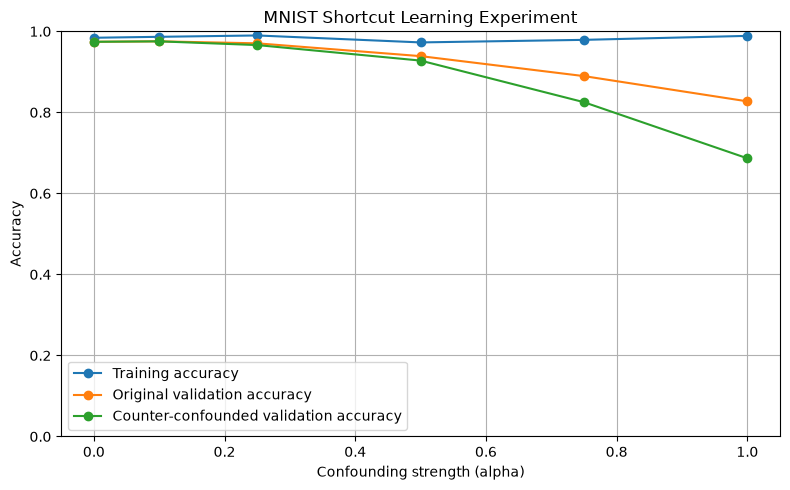

In [8]:
import copy
import io
import contextlib
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms


# One pixel location assigned to each digit class
PIXEL_LOCATIONS = [
    (3, 3),    # digit 0
    (3, 10),   # digit 1
    (3, 17),   # digit 2
    (10, 3),   # digit 3
    (10, 10),  # digit 4
    (10, 17),  # digit 5
    (17, 3),   # digit 6
    (17, 10),  # digit 7
    (17, 17),  # digit 8
    (24, 14),  # digit 9
]


class ConfoundedMNIST(Dataset):
    def __init__(self, root, train, alpha, mode):
        self.dataset = datasets.MNIST(
            root=root,
            train=train,
            download=True,
            transform=transforms.ToTensor(),
        )

        self.alpha = alpha
        self.mode = mode

        # Standard MNIST normalization
        self.mean = 0.1307
        self.std = 0.3081

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, label = self.dataset[index]
        image = image.clone()

        if self.mode == "target":
            indicated_class = label

        elif self.mode == "counter":
            indicated_class = (label + 1) % 10

        else:
            indicated_class = None

        if indicated_class is not None:
            row, col = PIXEL_LOCATIONS[indicated_class]

            old_value = image[0, row, col]
            image[0, row, col] = (
                (1 - self.alpha) * old_value + self.alpha
            )

        image = (image - self.mean) / self.std

        return image, label


def train_one_epoch(model, loader, device, optimizer):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for data, target in loader:
        data = data.to(device)
        target = target.to(device)

        optimizer.zero_grad()

        output = model(data)
        loss = F.cross_entropy(output, target)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * data.size(0)
        predictions = output.argmax(dim=1)
        correct += (predictions == target).sum().item()
        total += data.size(0)

    return total_loss / total, correct / total


def evaluate_accuracy(model, loader, device):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for data, target in loader:
            data = data.to(device)
            target = target.to(device)

            output = model(data)
            predictions = output.argmax(dim=1)

            correct += (predictions == target).sum().item()
            total += data.size(0)

    return correct / total


alphas = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0]

training_accuracies = []
original_validation_accuracies = []
counter_validation_accuracies = []

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for alpha in alphas:
    print(f"Training alpha = {alpha}")

    # Confounded training data
    train_dataset = ConfoundedMNIST(
        root="data",
        train=True,
        alpha=alpha,
        mode="target",
    )

    # Original, unmodified validation data
    original_val_dataset = ConfoundedMNIST(
        root="data",
        train=False,
        alpha=0.0,
        mode="none",
    )

    # Counter-confounded validation data
    counter_val_dataset = ConfoundedMNIST(
        root="data",
        train=False,
        alpha=alpha,
        mode="counter",
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=256,
        shuffle=True,
    )

    original_val_loader = DataLoader(
        original_val_dataset,
        batch_size=1000,
        shuffle=False,
    )

    counter_val_loader = DataLoader(
        counter_val_dataset,
        batch_size=1000,
        shuffle=False,
    )

    model = SingleHiddenLayerNet(hidden_size=64).to(device)

    optimizer = optim.Adadelta(
        model.parameters(),
        lr=1.0,
    )

    scheduler = StepLR(
        optimizer,
        step_size=1,
        gamma=0.7,
    )

    best_state = None
    best_original_val_accuracy = 0.0
    epochs_without_improvement = 0
    patience = 2

    for epoch in range(10):
        train_one_epoch(
            model,
            train_loader,
            device,
            optimizer,
        )

        original_val_accuracy = evaluate_accuracy(
            model,
            original_val_loader,
            device,
        )

        if original_val_accuracy > best_original_val_accuracy:
            best_original_val_accuracy = original_val_accuracy
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        scheduler.step()

        if epochs_without_improvement >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    train_accuracy = evaluate_accuracy(
        model,
        train_loader,
        device,
    )

    original_val_accuracy = evaluate_accuracy(
        model,
        original_val_loader,
        device,
    )

    counter_val_accuracy = evaluate_accuracy(
        model,
        counter_val_loader,
        device,
    )

    training_accuracies.append(train_accuracy)
    original_validation_accuracies.append(original_val_accuracy)
    counter_validation_accuracies.append(counter_val_accuracy)

    print(
        f"Training accuracy: {train_accuracy:.4f} | "
        f"Original validation accuracy: {original_val_accuracy:.4f} | "
        f"Counter-confounded accuracy: {counter_val_accuracy:.4f}"
    )


plt.figure(figsize=(8, 5))

plt.plot(
    alphas,
    training_accuracies,
    marker="o",
    label="Training accuracy",
)

plt.plot(
    alphas,
    original_validation_accuracies,
    marker="o",
    label="Original validation accuracy",
)

plt.plot(
    alphas,
    counter_validation_accuracies,
    marker="o",
    label="Counter-confounded validation accuracy",
)

plt.xlabel("Confounding strength (alpha)")
plt.ylabel("Accuracy")
plt.title("MNIST Shortcut Learning Experiment")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Explanation

As the confounding strength, alpha, increases, the artificial class-dependent pixel becomes more informative. The model can therefore achieve high training accuracy by relying on this shortcut instead of learning the actual digit shapes. Performance on the original validation data may decrease because the shortcut is absent. Performance on the counter-confounded validation data should decrease substantially because the artificial feature indicates the wrong class. This demonstrates shortcut learning: good training performance does not necessarily mean that the model learned the intended visual features.

At the strongest confounding level, the model achieved approximately 99% training accuracy, while original validation accuracy dropped to about 83% and counter-confounded accuracy dropped to about 69%. This gap shows that high training accuracy can be misleading when the model learns a spurious feature.

# Task 01 - Part 5: Final Evaluation

Now perform a final evaluation of your model using the MNIST test set. Based on the experiments you performed above, choose the architecture and training configuration that you believe performs best.

Using only the training and validation data to make your design decisions:

* Select your final network architecture.
* Select the training parameters you will use.
* Train a new instance of the model.
* Evaluate the best saved model checkpoint on the MNIST test set.
* Report the final test loss and classification accuracy.

Do not use the test set to make additional changes to the architecture or training process after evaluating the model.

Briefly compare the final test performance with the validation performance you observed during development. Discuss whether the test results are consistent with what you expected based on the validation data.

Note: Your grade does not depend on final performance. You will be graded on the experiments you perform, how well you explored the space of model architectures, and the insights you gained from them.


In [11]:
import copy
import torch
import torch.nn.functional as F


def evaluate_metrics(model, device, data_loader):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    with torch.no_grad():
        for data, target in data_loader:
            data = data.to(device)
            target = target.to(device)

            output = model(data)
            loss = F.cross_entropy(output, target)

            total_loss += loss.item() * data.size(0)

            predictions = output.argmax(dim=1)
            total_correct += (predictions == target).sum().item()
            total_examples += data.size(0)

    average_loss = total_loss / total_examples
    accuracy = total_correct / total_examples

    return average_loss, accuracy


# Final architecture and training configuration
final_training_params = TrainingParameters(
    epochs=10,
    batch_size=256,
    test_batch_size=1000,
    lr=1.0,
    gamma=0.7,
    dry_run=False,
    save_model=False,
)

device, train_kwargs, test_kwargs = configure_training_device(
    final_training_params
)

transform = build_preprocessing_transform(final_training_params)

train_loader, val_loader, test_loader = build_data_loaders(
    train_kwargs,
    test_kwargs,
    transform
)


# Final model: one hidden layer with 256 neurons
final_model = SingleHiddenLayerNet(hidden_size=256).to(device)

optimizer = optim.Adadelta(
    final_model.parameters(),
    lr=final_training_params.lr
)

scheduler = StepLR(
    optimizer,
    step_size=1,
    gamma=final_training_params.gamma
)


best_val_loss = float("inf")
best_val_accuracy = 0.0
best_state = None
epochs_without_improvement = 0
patience = 2


# Train using only training and validation data
for epoch in range(1, final_training_params.epochs + 1):
    train_loss = run_training_epoch_tracking(
        final_training_params,
        final_model,
        device,
        train_loader,
        optimizer
    )

    val_loss, val_accuracy = evaluate_metrics(
        final_model,
        device,
        val_loader
    )

    print(
        f"Epoch {epoch}: "
        f"training loss = {train_loss:.4f}, "
        f"validation loss = {val_loss:.4f}, "
        f"validation accuracy = {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_accuracy = val_accuracy
        best_state = copy.deepcopy(final_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    scheduler.step()

    if epochs_without_improvement >= patience:
        print("Early stopping.")
        break


# Restore the best validation checkpoint
final_model.load_state_dict(best_state)


# Evaluate on the test set only after model selection is complete
test_loss, test_accuracy = evaluate_metrics(
    final_model,
    device,
    test_loader
)

print("\nFinal model results")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Best validation accuracy: {best_val_accuracy:.4f}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Epoch 1: training loss = 0.3055, validation loss = 0.1390, validation accuracy = 0.9557
Epoch 2: training loss = 0.1011, validation loss = 0.0980, validation accuracy = 0.9702
Epoch 3: training loss = 0.0676, validation loss = 0.0838, validation accuracy = 0.9715
Epoch 4: training loss = 0.0510, validation loss = 0.0761, validation accuracy = 0.9745
Epoch 5: training loss = 0.0418, validation loss = 0.0710, validation accuracy = 0.9775
Epoch 6: training loss = 0.0361, validation loss = 0.0701, validation accuracy = 0.9775
Epoch 7: training loss = 0.0328, validation loss = 0.0673, validation accuracy = 0.9797
Epoch 8: training loss = 0.0304, validation loss = 0.0675, validation accuracy = 0.9797
Epoch 9: training loss = 0.0289, validation loss = 0.0667, validation accuracy = 0.9795
Epoch 10: training loss = 0.0278, validation loss = 0.0664, validation accuracy = 0.9792

Final model results
Best validation loss: 0.0664
Best validation accuracy: 0.9792
Test loss: 0.0615
Test accuracy: 0.9

**Explination**

Based on the width and depth experiments, I selected a network with one hidden layer containing 256 neurons. The model was trained using the training data, while the validation data was used for early stopping and checkpoint selection. The test set was not used to make architecture or training decisions. After restoring the checkpoint with the best validation loss, the model was evaluated once on the MNIST test set.
The final test loss and accuracy were compared with the best validation results. The test performance was expected to be similar to the validation performance because both datasets contain unseen MNIST examples. Small differences are normal because the validation and test sets contain different images.